# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
## library imports here
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

# strings for the purposes of plotting
ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

There are 273 patients in the dataset, and the four chest pain types are not equally common. Type 0 (asymptomatic) is the most common, with 128 patients, or about 47%. Type 2 (atypical angina) comes next with 81 patients (about 30%), then Type 1 (typical angina) with 44 patients (about 16%). Type 3 (non-anginal pain) is the rarest, with only 20 patients (about 7%). This means the classes are unbalanced: Type 0 has more than six times as many patients as Type 3. Because of this, a model will probably guess Type 0 most of the time and will have trouble correctly finding the rare types, especially Type 3.

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

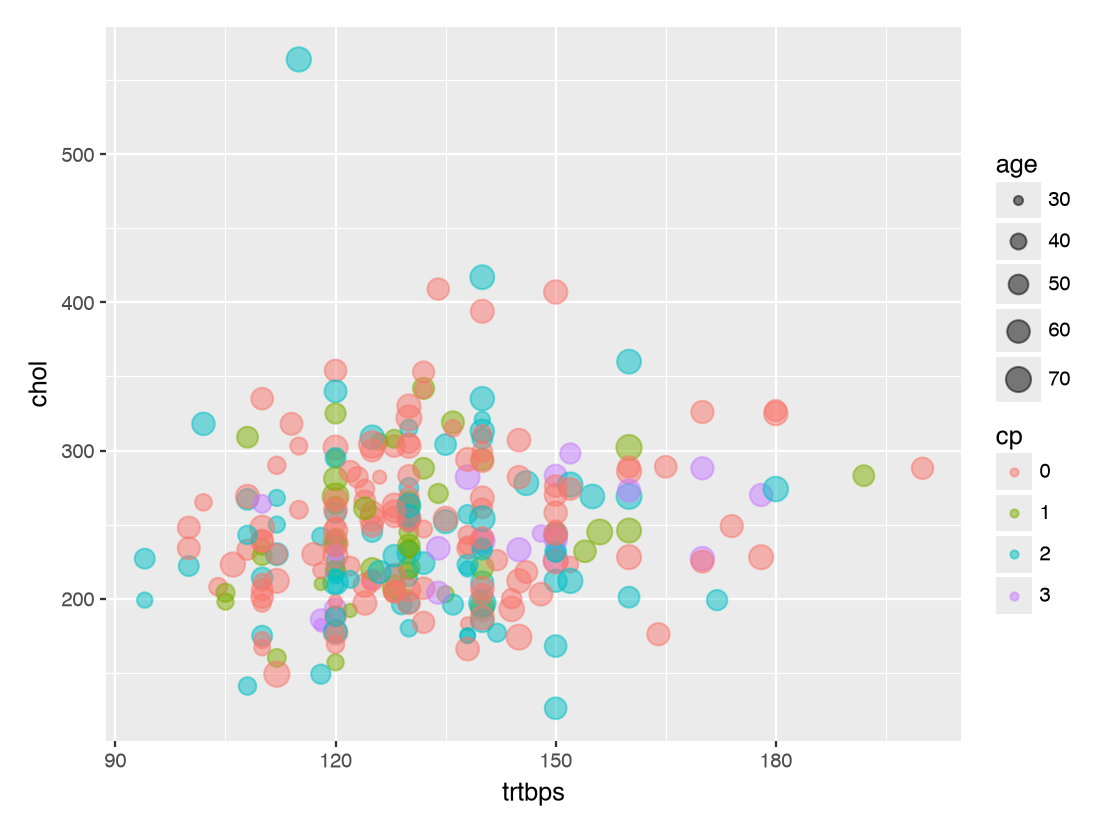

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


The 10-nearest neighbors model does not do a good job of predicting chest pain type. The test accuracy is 0.414, so the model guesses the right type only about 41% of the time. The macro precision (0.228), macro recall (0.245), and macro F1 (0.218) are even lower. Looking at each class, Type 0 has a recall of 0.75 but a precision of only 0.464. The model predicted Type 0 for 207 patients, even though only 128 patients are actually Type 0, so it catches most of the real Type 0 patients but also puts many other patients into that group by mistake. Type 1 (F1 = 0.07) and Type 2 (F1 = 0.227) do poorly. Type 3 has precision, recall, and F1 of exactly 0: the model guessed Type 3 only 2 times and was wrong both times, and on the training data it never predicted Type 3 at all (it doesn’t even show up in the plot). These weird values happen because the classes are unbalanced. Type 0 is almost half of the patients, and Type 3 is only 20 out of 273. When the model looks at a patient’s 10 closest neighbors, most of them are usually Type 0, so Type 0 wins the vote most of the time and the rare types almost never win. Accuracy looks better than the macro scores because it is mostly driven by the big Type 0 group, while the macro scores give each class equal weight, so the poor scores for the rare classes pull them down. The plot also shows that the chest pain types are all mixed together, which means blood pressure, cholesterol, and age are not very good at telling the types apart.


In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = ha[["trtbps", "chol", "age"]]
y = ha["cp"]

knn_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

knn_pipe.fit(X, y)
knn_probs = pd.DataFrame(knn_pipe.predict_proba(X),
                         columns=["P(cp=" + c + ")" for c in knn_pipe.classes_])
ha["knn_pred"] = knn_pipe.predict(X)
knn_probs

,P(cp=0),P(cp=1),P(cp=2),P(cp=3)
0,0.5,0.1,0.1,0.3
1,0.2,0.1,0.6,0.1
2,0.2,0.5,0.3,0.0
3,0.7,0.2,0.1,0.0
4,0.6,0.1,0.2,0.1
...,...,...,...,...
268,0.3,0.1,0.5,0.1
269,0.5,0.2,0.2,0.1
270,0.4,0.1,0.4,0.1
271,0.7,0.1,0.1,0.1


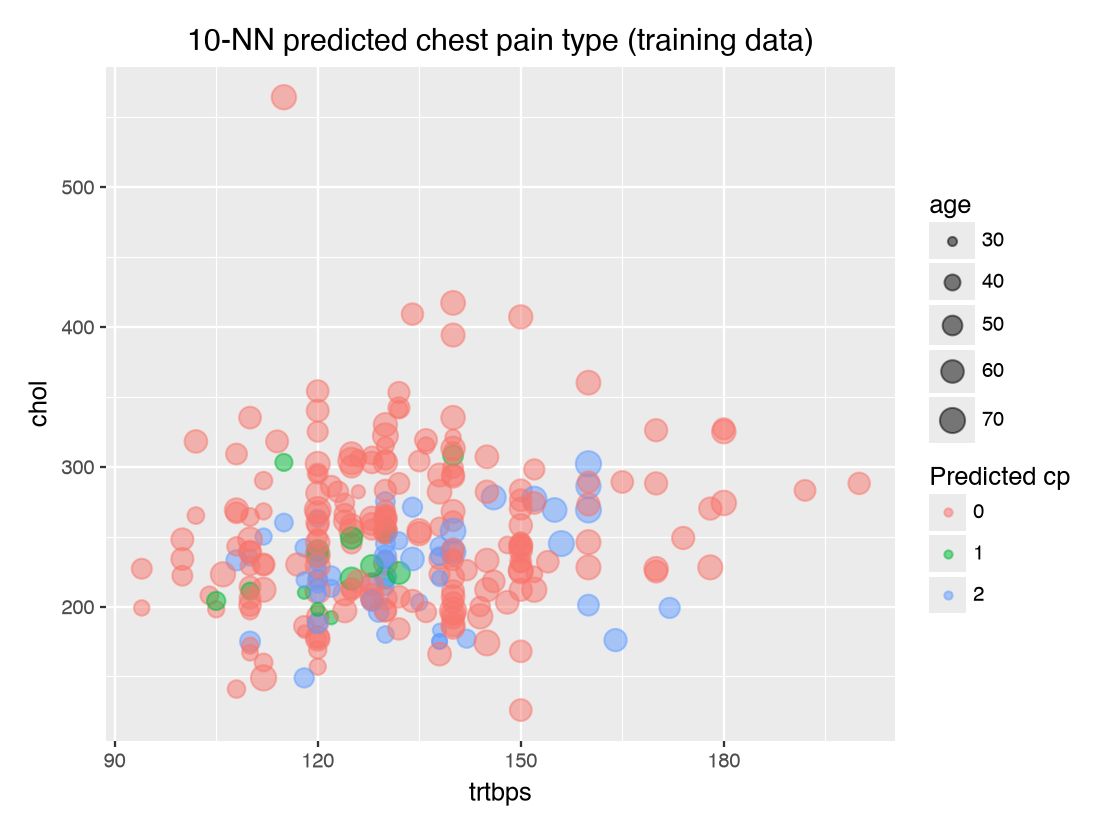

In [6]:
(ggplot(ha, aes(x="trtbps", y="chol", size="age", color="knn_pred"))
 + geom_point(alpha=0.5)
 + labs(title="10-NN predicted chest pain type (training data)", color="Predicted cp"))

In [7]:
y_cv = cross_val_predict(knn_pipe, X, y, cv=5)

print("Accuracy:        ", round(accuracy_score(y, y_cv), 3))
print("Macro precision: ", round(precision_score(y, y_cv, average="macro", zero_division=0), 3))
print("Macro recall:    ", round(recall_score(y, y_cv, average="macro", zero_division=0), 3))
print("Macro F1:        ", round(f1_score(y, y_cv, average="macro", zero_division=0), 3))

classes = ["0", "1", "2", "3"]
pd.DataFrame({
    "precision":   precision_score(y, y_cv, labels=classes, average=None, zero_division=0),
    "recall":      recall_score(y, y_cv, labels=classes, average=None, zero_division=0),
    "f1":          f1_score(y, y_cv, labels=classes, average=None, zero_division=0),
    "n_true":      [(y == c).sum() for c in classes],
    "n_predicted": [(y_cv == c).sum() for c in classes],
}, index=["cp = " + c for c in classes]).round(3)

Accuracy:         0.414
Macro precision:  0.228
Macro recall:     0.245
Macro F1:         0.218


,precision,recall,f1,n_true,n_predicted
cp = 0,0.464,0.750,0.573,128,207
cp = 1,0.154,0.045,0.070,44,13
cp = 2,0.294,0.185,0.227,81,51
cp = 3,0.000,0.000,0.000,20,2


## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

The logistic regression model is not able to find Class 3 patients at all. The test precision, recall, and F1 score for Class 3 are all 0.0, and the model predicted 0 out of the 20 real Class 3 patients as Class 3. The predicted probabilities show why: the chance of being Class 3 is small for every patient (about 0.04 to 0.12), so it never gets above the 0.5 cutoff the model uses to say “yes, this is Class 3.” Because of this, the model predicts “not Class 3” for every patient, and the plot shows only one color (0). This happens because Class 3 is very rare, only 20 out of 273 patients (about 7%). The model can be right about 93% of the time just by always saying “not Class 3,” so that’s what it does. Recall is 0 because the model found none of the 20 real Class 3 patients. Since it never predicted Class 3, precision is 0 divided by 0, which can’t be calculated, so Python reports it as 0. F1 is 0 because both precision and recall are 0. Blood pressure, cholesterol, and age are not strong enough to pick out this small group.

In [8]:
y3 = ha["cp_is_3"]

logit3 = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression())
])

logit3.fit(X, y3)
probs3 = pd.DataFrame(logit3.predict_proba(X), columns=["P(not 3)", "P(cp=3)"])
ha["pred_is_3"] = logit3.predict(X).astype(str)
probs3

,P(not 3),P(cp=3)
0,0.901104,0.098896
1,0.941224,0.058776
2,0.951037,0.048963
3,0.971022,0.028978
4,0.898105,0.101895
...,...,...
268,0.801764,0.198236
269,0.917096,0.082904
270,0.967963,0.032037
271,0.885371,0.114629


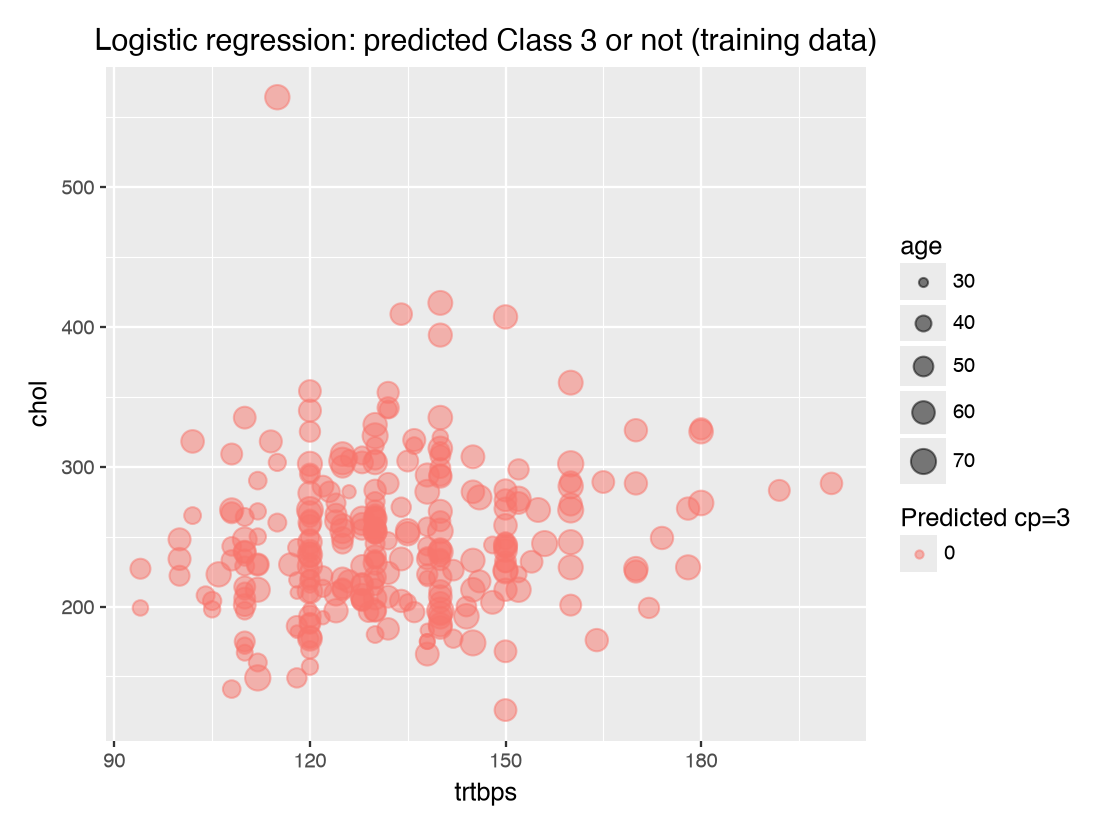

In [9]:
(ggplot(ha, aes(x="trtbps", y="chol", size="age", color="pred_is_3"))
 + geom_point(alpha=0.5)
 + labs(title="Logistic regression: predicted Class 3 or not (training data)",
        color="Predicted cp=3"))

In [10]:
y3_cv = cross_val_predict(logit3, X, y3, cv=5)

print("Precision (class 3):", round(precision_score(y3, y3_cv, zero_division=0), 3))
print("Recall (class 3):   ", round(recall_score(y3, y3_cv, zero_division=0), 3))
print("F1 (class 3):       ", round(f1_score(y3, y3_cv, zero_division=0), 3))
print("Number predicted as class 3:", y3_cv.sum(), "out of", y3.sum(), "real class 3 patients")

Precision (class 3): 0.0
Recall (class 3):    0.0
F1 (class 3):        0.0
Number predicted as class 3: 0 out of 20 real class 3 patients


## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

========== Class 0 ==========


,P(not 0),P(cp=0)
0,0.478092,0.521908
1,0.678292,0.321708
2,0.504099,0.495901
3,0.443054,0.556946
4,0.543651,0.456349
5,0.507843,0.492157
6,0.600599,0.399401
7,0.630345,0.369655
8,0.568618,0.431382
9,0.550279,0.449721


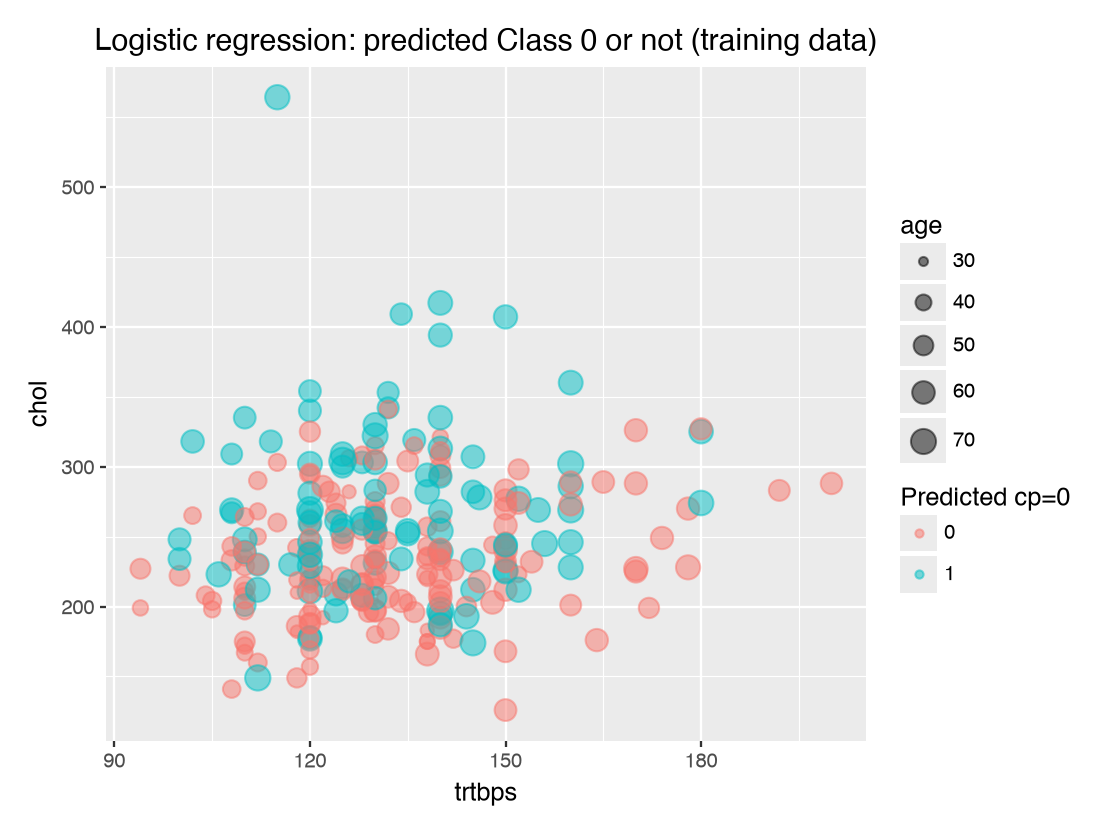

========== Class 1 ==========


,P(not 1),P(cp=1)
0,0.894867,0.105133
1,0.734949,0.265051
2,0.845941,0.154059
3,0.820938,0.179062
4,0.876054,0.123946
5,0.849236,0.150764
6,0.767814,0.232186
7,0.877052,0.122948
8,0.887602,0.112398
9,0.852491,0.147509


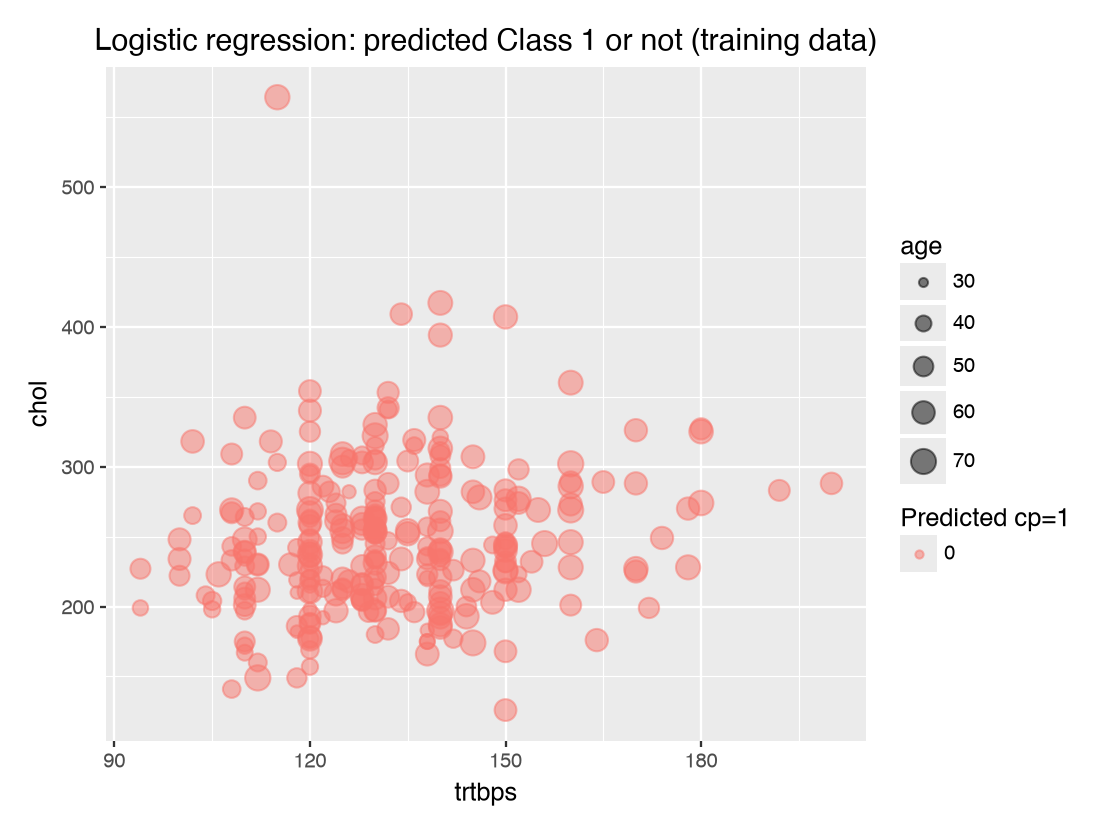

========== Class 2 ==========


,P(not 2),P(cp=2)
0,0.731442,0.268558
1,0.638588,0.361412
2,0.706497,0.293503
3,0.753821,0.246179
4,0.693586,0.306414
5,0.729453,0.270547
6,0.671777,0.328223
7,0.678633,0.321367
8,0.684284,0.315716
9,0.701075,0.298925


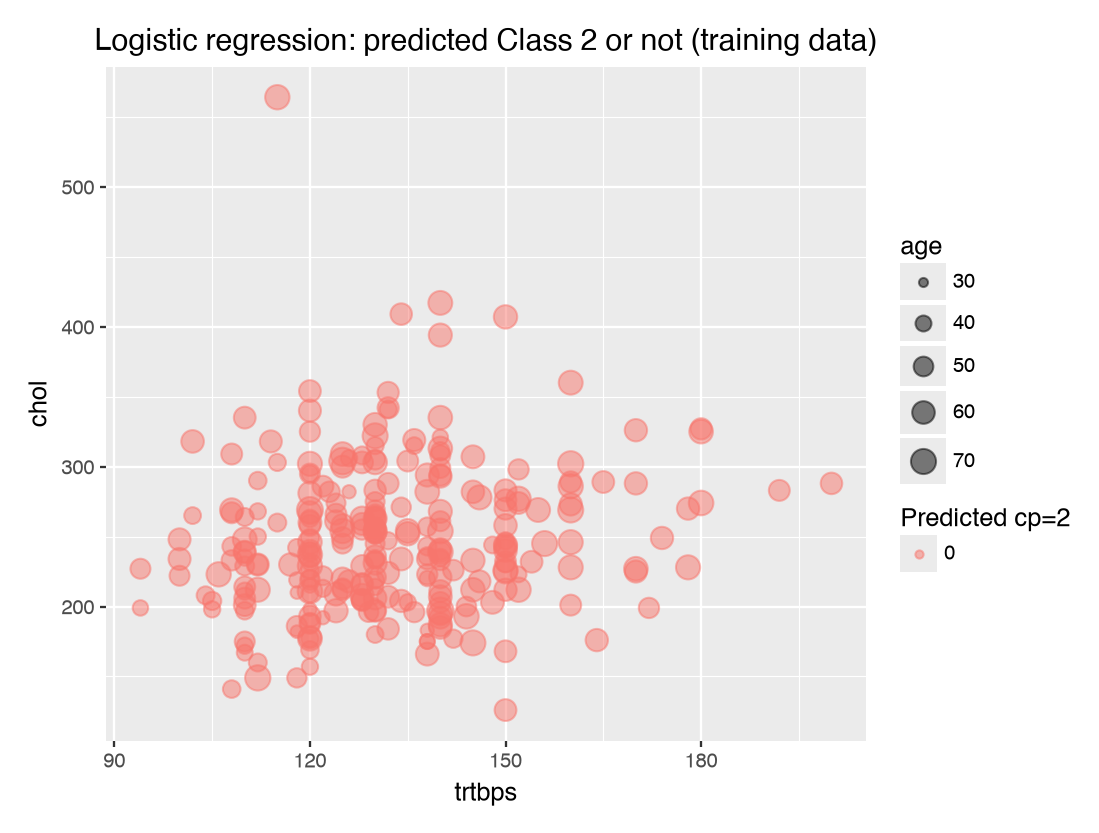

In [11]:
from sklearn.metrics import roc_auc_score

results = []

for c in ["0", "1", "2", "3"]:
    y_c = ha["cp_is_" + c]

    logit_c = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression())
    ])

    # training data: probabilities + predicted classes
    logit_c.fit(X, y_c)
    probs_c = pd.DataFrame(logit_c.predict_proba(X), columns=["P(not " + c + ")", "P(cp=" + c + ")"])
    ha["pred_is_" + c] = logit_c.predict(X).astype(str)

    if c != "3":   # class 3 was already shown in Q2
        print("========== Class", c, "==========")
        display(probs_c.head(10))
        display(ggplot(ha, aes(x="trtbps", y="chol", size="age", color="pred_is_" + c))
                + geom_point(alpha=0.5)
                + labs(title="Logistic regression: predicted Class " + c + " or not (training data)",
                       color="Predicted cp=" + c))

    # test estimates with 5-fold cross-validation
    y_cv = cross_val_predict(logit_c, X, y_c, cv=5)
    p_cv = cross_val_predict(logit_c, X, y_c, cv=5, method="predict_proba")[:, 1]
    results.append({
        "class": c,
        "precision": precision_score(y_c, y_cv, zero_division=0),
        "recall": recall_score(y_c, y_cv, zero_division=0),
        "f1": f1_score(y_c, y_cv, zero_division=0),
        "roc_auc": roc_auc_score(y_c, p_cv),
        "n_true": int(y_c.sum()),
        "n_predicted": int(y_cv.sum()),
    })

In [12]:
ovr_results = pd.DataFrame(results).set_index("class").round(3)
ovr_results

,precision,recall,f1,roc_auc,n_true,n_predicted
class,,,,,,
0,0.515,0.414,0.459,0.561,128,103
1,0.000,0.000,0.000,0.584,44,0
2,0.000,0.000,0.000,0.485,81,0
3,0.000,0.000,0.000,0.591,20,0


I repeated the one-vs-rest logistic regression for Classes 0, 1, and 2. Class 0 was the only class the model ever predicted: it had a precision of 0.515, a recall of 0.414, and an F1 score of 0.459. For Classes 1 and 2, the predicted probabilities were always low (about 0.10 to 0.27 for Class 1 and about 0.25 to 0.36 for Class 2), so they never passed the 0.5 cutoff. The model predicted “no” for every patient, the plots show only one color, and precision, recall, and F1 were all 0, the same as Class 3 in Q2. So based on precision, recall, and F1, the OvR approach was best at distinguishing Class 0. This makes sense because Class 0 is the biggest group (128 of 273 patients), so its probabilities are often close to or above 0.5 and the model actually predicts it. The plot for Class 0 is also the only one with two colors. I also looked at ROC-AUC, which checks how well the probabilities separate a class from the rest without using the 0.5 cutoff. By this measure, Class 3 (0.591) and Class 1 (0.584) were slightly higher than Class 0 (0.561), and Class 2 (0.485) was even worse than random guessing. However, all of these values are close to 0.5, which means none of the classes are separated well. Overall, blood pressure, cholesterol, and age are not good predictors of chest pain type. Class 0 is the only class the model can pick out in a useful way, and that’s mainly because it’s the most common class.

## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [13]:
from sklearn.model_selection import cross_val_score

# keep only chest pain types 0 and 1
ha_01 = ha[ha["cp"].isin(["0", "1"])]
X_01 = ha_01[["trtbps", "chol", "age"]]
y_01 = ha_01["cp_is_1"]     # 1 = type 1, 0 = type 0

logit_01 = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression())
])

# estimate the test ROC-AUC with 5-fold cross-validation
auc_01 = cross_val_score(logit_01, X_01, y_01, cv=5, scoring="roc_auc")

print("Number of patients:", len(ha_01))
print("ROC-AUC for each fold:", auc_01.round(3))
print("Average ROC-AUC (0 vs 1):", round(auc_01.mean(), 3))

Number of patients: 172
ROC-AUC for each fold: [0.573 0.769 0.684 0.573 0.409]
Average ROC-AUC (0 vs 1): 0.602


I reduced the dataset to only chest pain types 0 and 1, which left 172 patients (128 Type 0 and 44 Type 1). Then I fit a logistic regression to predict between the two groups and estimated the ROC-AUC with 5-fold cross-validation. The average ROC-AUC was 0.602. This means that if I pick one random Type 1 patient and one random Type 0 patient, the model gives the Type 1 patient a higher chance of being Type 1 about 60% of the time. That’s a little better than random guessing (0.5), but still far from perfect (1.0). The ROC-AUC also changed a lot from fold to fold, from 0.409 to 0.769, so the model is not very stable. This is probably because there are only 44 Type 1 patients, so each fold has just a few of them. Overall, blood pressure, cholesterol, and age can only slightly tell Type 0 and Type 1 apart. Still, 0.602 is a bit higher than the one-vs-rest AUCs for Class 0 (0.561) and Class 1 (0.584), because comparing just two groups is an easier job than comparing one group against all the others.

## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

In [14]:
ovo_results = [{
    "pair": "0 vs 1",
    "n_patients": len(ha_01),
    "roc_auc": auc_01.mean(),
    "lowest_fold": auc_01.min(),
    "highest_fold": auc_01.max(),
}]

for c in ["2", "3"]:
    # keep only chest pain type 0 and type c
    ha_pair = ha[ha["cp"].isin(["0", c])]
    X_pair = ha_pair[["trtbps", "chol", "age"]]
    y_pair = ha_pair["cp_is_" + c]     # 1 = type c, 0 = type 0

    logit_pair = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression())
    ])

    auc_pair = cross_val_score(logit_pair, X_pair, y_pair, cv=5, scoring="roc_auc")
    print("0 vs " + c + " ROC-AUC for each fold:", auc_pair.round(3))

    ovo_results.append({
        "pair": "0 vs " + c,
        "n_patients": len(ha_pair),
        "roc_auc": auc_pair.mean(),
        "lowest_fold": auc_pair.min(),
        "highest_fold": auc_pair.max(),
    })

pd.DataFrame(ovo_results).set_index("pair").round(3)

0 vs 2 ROC-AUC for each fold: [0.409 0.726 0.596 0.685 0.38 ]
0 vs 3 ROC-AUC for each fold: [0.423 0.452 0.808 0.73  0.38 ]


,n_patients,roc_auc,lowest_fold,highest_fold
pair,,,,
0 vs 1,172,0.602,0.409,0.769
0 vs 2,209,0.559,0.380,0.726
0 vs 3,148,0.559,0.380,0.808


I repeated the steps from Q4 for two more pairs: Type 0 vs Type 2 (209 patients) and Type 0 vs Type 3 (148 patients). Both pairs had an average ROC-AUC of 0.559, while Type 0 vs Type 1 had 0.602. So the OvO approach was best at distinguishing Type 0 from Type 1. Even so, the difference is small, and all three AUCs are only a little above 0.5, which means the model is just slightly better than random guessing for every pair. The scores also jumped around a lot between folds. For 0 vs 3, the fold AUCs ranged from 0.380 to 0.808. That’s because there are only 20 Type 3 patients, so each fold has just about 4 of them, and one or two patients can change the score a lot. For 0 vs 2, they ranged from 0.380 to 0.726. Because the scores are this unstable, I can’t be very confident that 0 vs 1 is really better than the other two pairs. Overall, blood pressure, cholesterol, and age are weak predictors of chest pain type, whether I use one-vs-rest or one-vs-one.